In [1]:
print("Jupyter berhasil dijalankan!")

Jupyter berhasil dijalankan!


In [2]:
import fitz
import os
import glob

# Folder PDF dan folder hasil JPG
pdf_folder = "pdf"
jpg_folder = "jpg"

# Membuat folder jpg jika belum ada
os.makedirs(jpg_folder, exist_ok=True)

# Mengambil semua file PDF
pdf_files = sorted(glob.glob(os.path.join(pdf_folder, "*.pdf")))

print(f"Jumlah PDF ditemukan: {len(pdf_files)}")

# Mengubah setiap PDF menjadi JPG
for pdf_path in pdf_files:
    doc = fitz.open(pdf_path)
    
    nama_file = os.path.splitext(os.path.basename(pdf_path))[0]
    
    for nomor_halaman, halaman in enumerate(doc):
        # Resolusi 2x agar gambar cukup jelas
        pix = halaman.get_pixmap(matrix=fitz.Matrix(2, 2), alpha=False)
        
        # Jika PDF hanya 1 halaman
        if len(doc) == 1:
            output_path = os.path.join(jpg_folder, f"{nama_file}.jpg")
        else:
            output_path = os.path.join(
                jpg_folder,
                f"{nama_file}_halaman_{nomor_halaman + 1}.jpg"
            )
        
        pix.save(output_path)
        print(f"Berhasil: {output_path}")
    
    doc.close()

print("\nSelesai! Semua PDF sudah dikonversi menjadi JPG.")

Jumlah PDF ditemukan: 9
Berhasil: jpg\ijazah 1.jpg
Berhasil: jpg\ijazah 2.jpg
Berhasil: jpg\ijazah 3.jpg
Berhasil: jpg\ijazah 4.jpg
Berhasil: jpg\ijazah 5.jpg
Berhasil: jpg\ijazah 6.jpg
Berhasil: jpg\ijazah 7.jpg
Berhasil: jpg\ijazah 8.jpg
Berhasil: jpg\ijazah 9.jpg

Selesai! Semua PDF sudah dikonversi menjadi JPG.


In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import glob
import os

# Mengambil semua file JPG
jpg_files = sorted(glob.glob("jpg/*.jpg"))

print("Jumlah gambar:", len(jpg_files))

for file in jpg_files:
    print(file)

Jumlah gambar: 9
jpg\ijazah 1.jpg
jpg\ijazah 2.jpg
jpg\ijazah 3.jpg
jpg\ijazah 4.jpg
jpg\ijazah 5.jpg
jpg\ijazah 6.jpg
jpg\ijazah 7.jpg
jpg\ijazah 8.jpg
jpg\ijazah 9.jpg


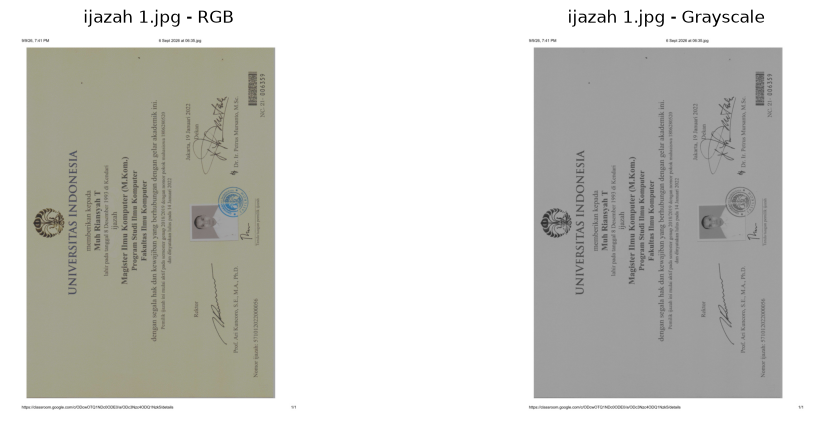

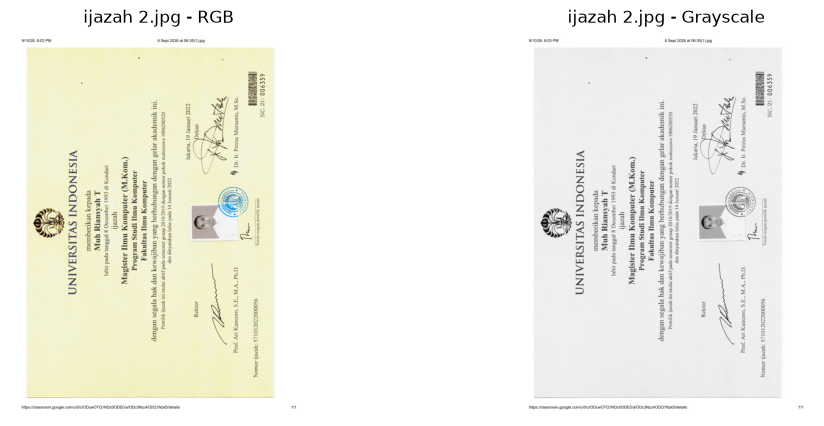

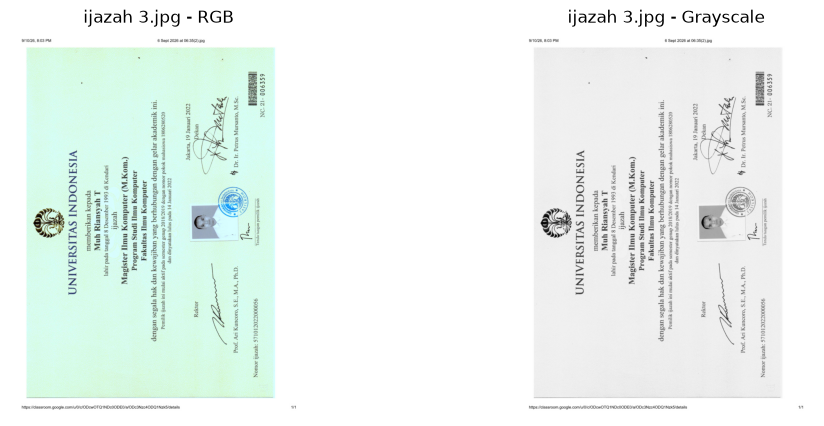

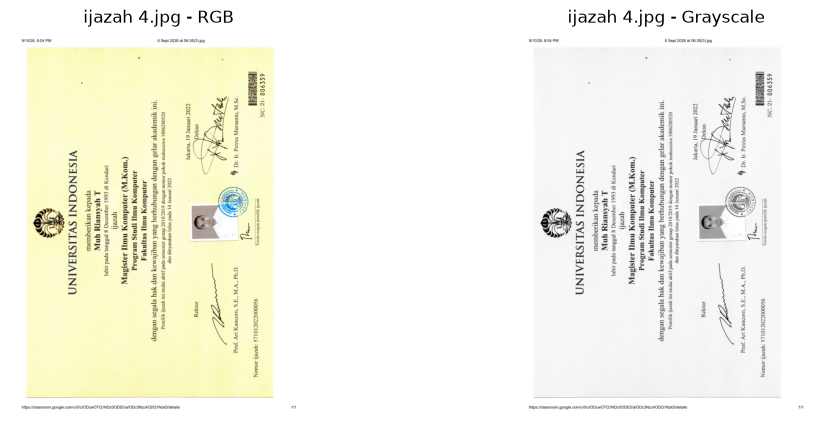

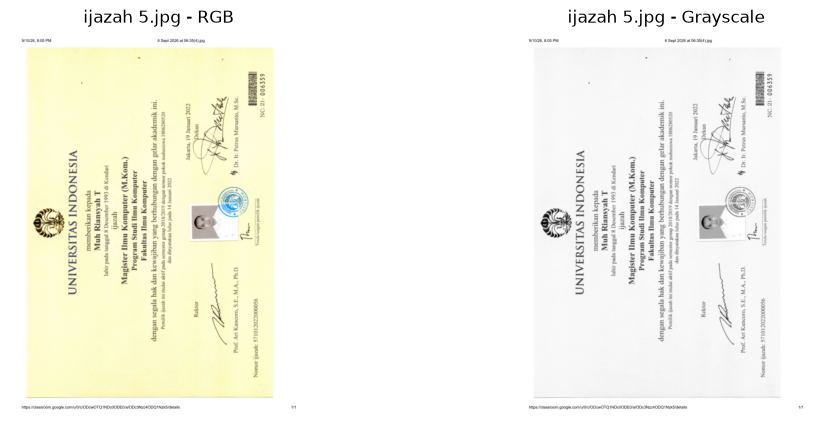

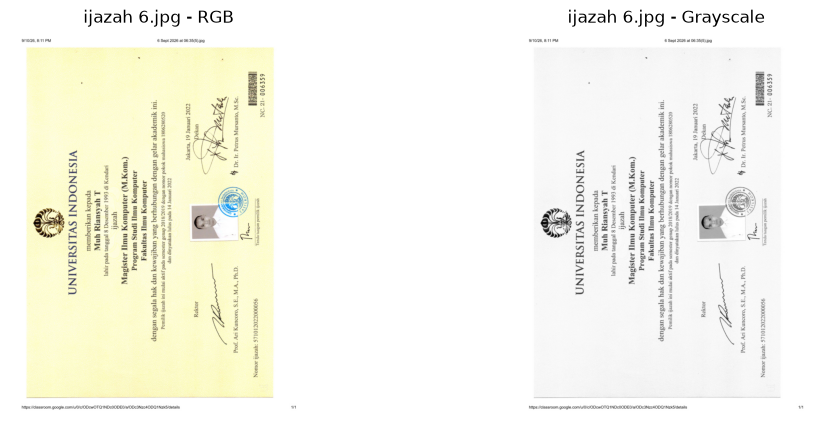

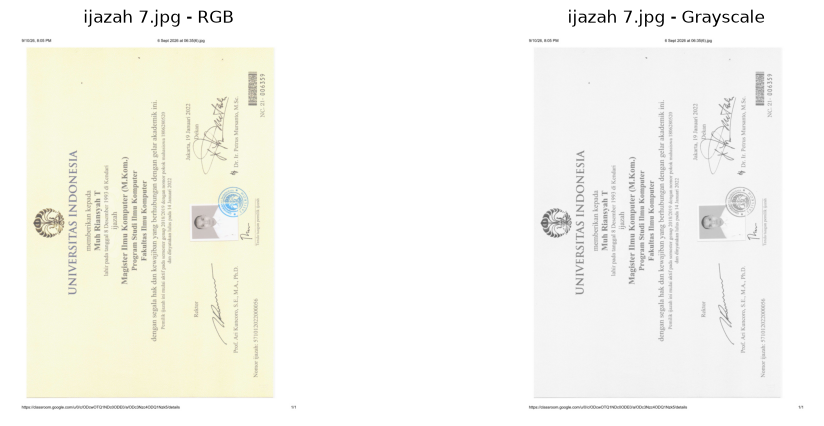

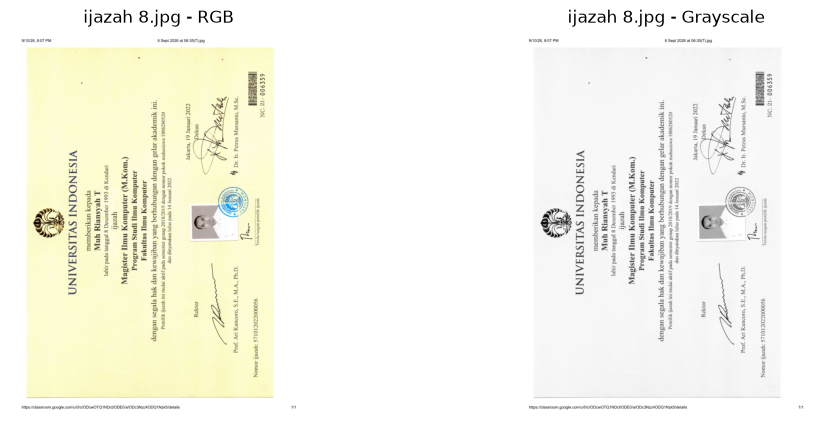

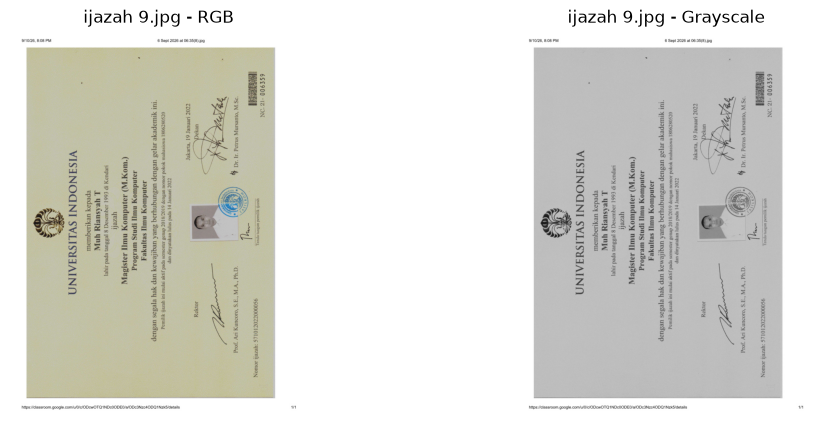

In [4]:
for file in jpg_files:
    
    # Membaca gambar
    img_bgr = cv2.imread(file)
    
    # Mengubah BGR menjadi RGB
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Mengubah RGB menjadi grayscale
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    # Nama gambar
    nama = os.path.basename(file)
    
    # Menampilkan RGB dan grayscale
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.imshow(img_rgb)
    plt.title(f"{nama} - RGB")
    plt.axis("off")
    
    plt.subplot(1, 2, 2)
    plt.imshow(gray, cmap="gray")
    plt.title(f"{nama} - Grayscale")
    plt.axis("off")
    
    plt.show()
    

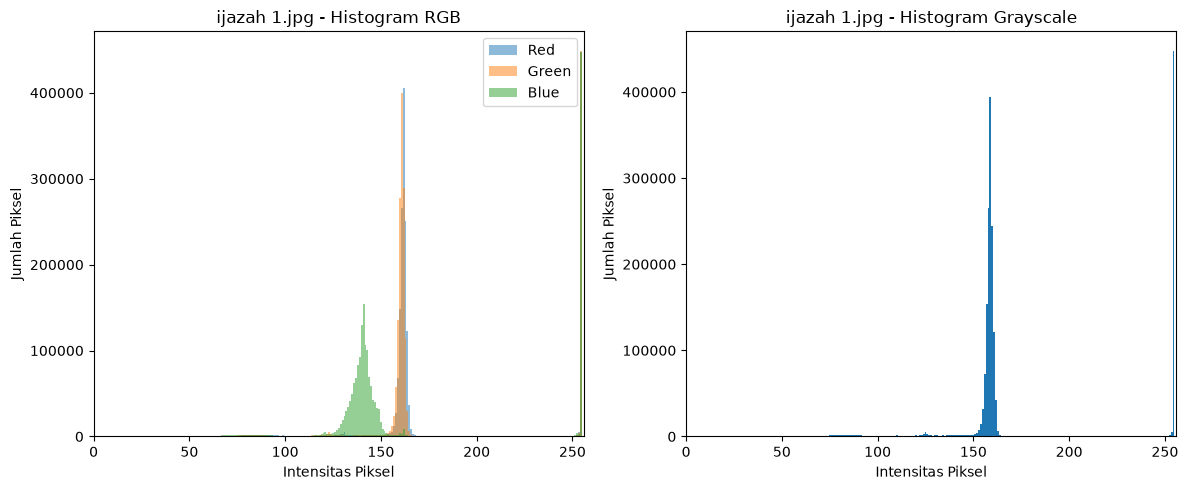

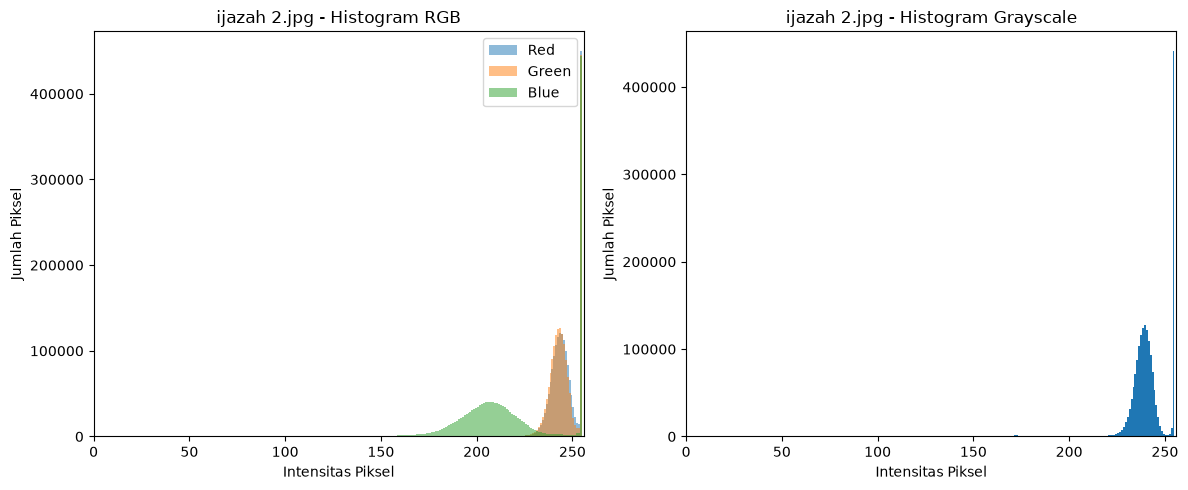

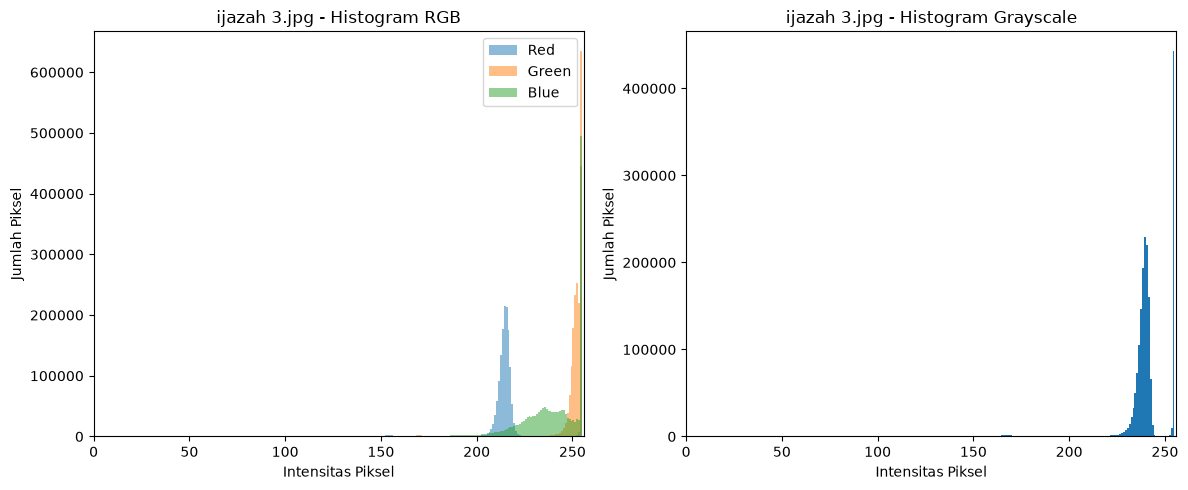

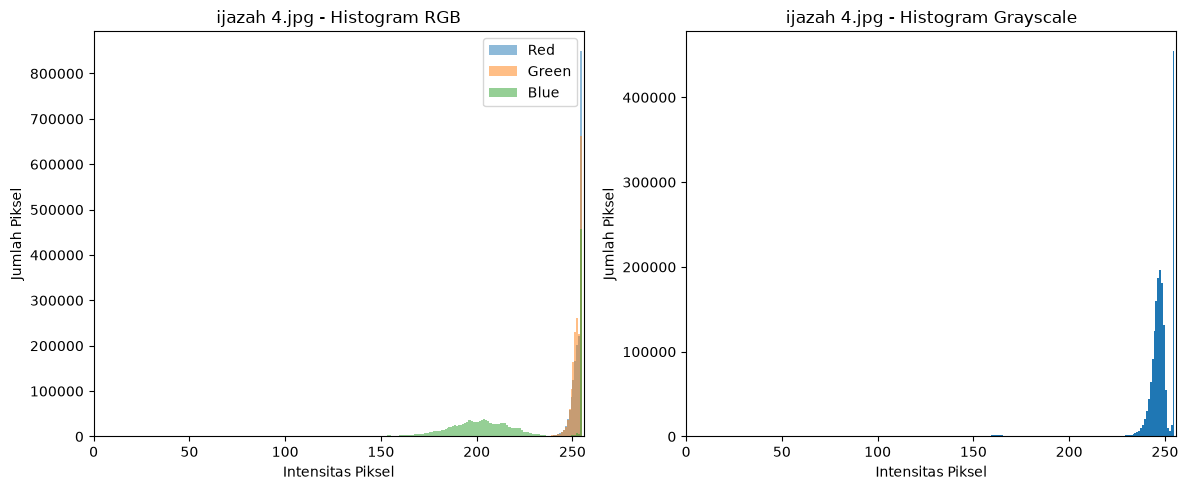

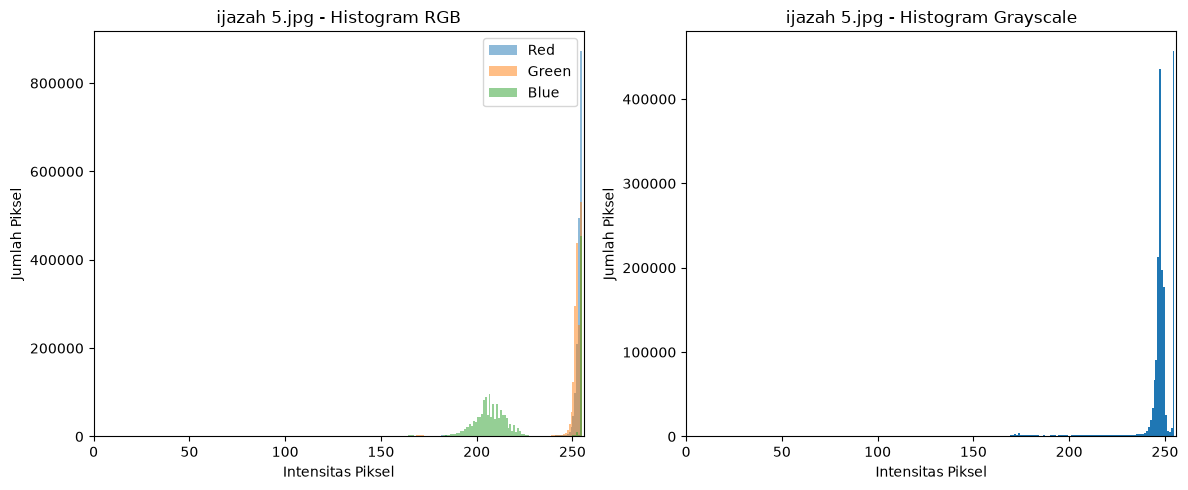

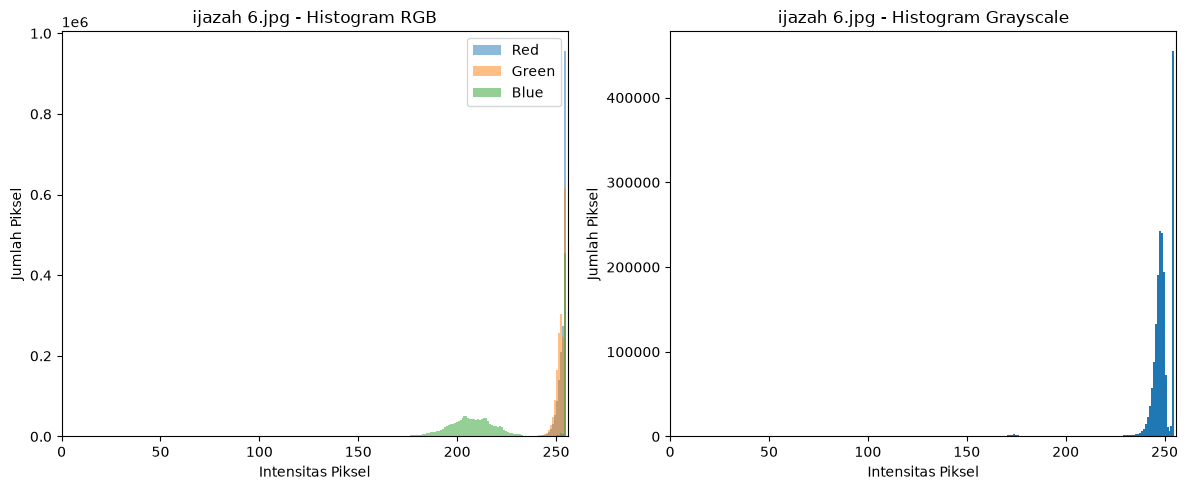

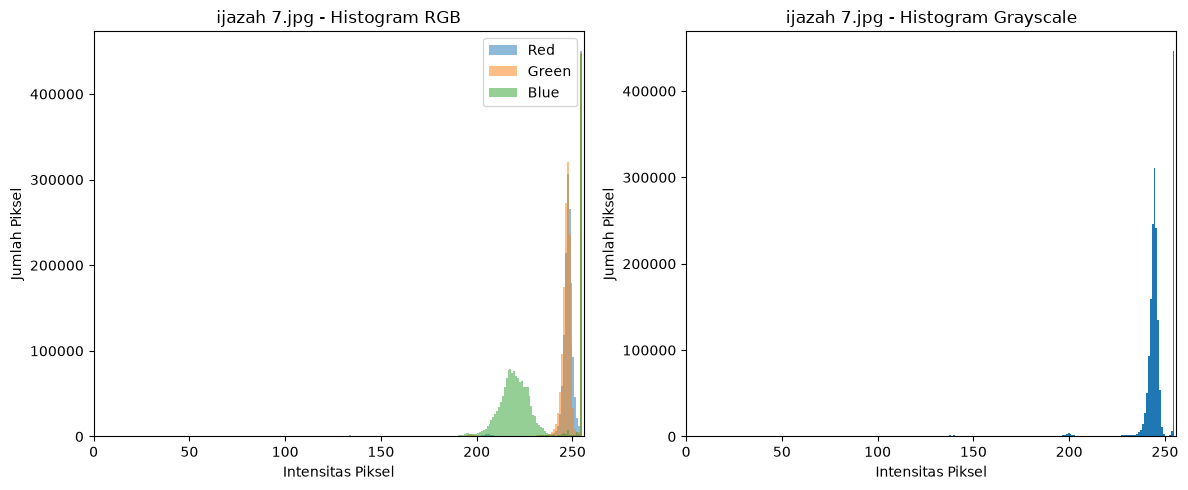

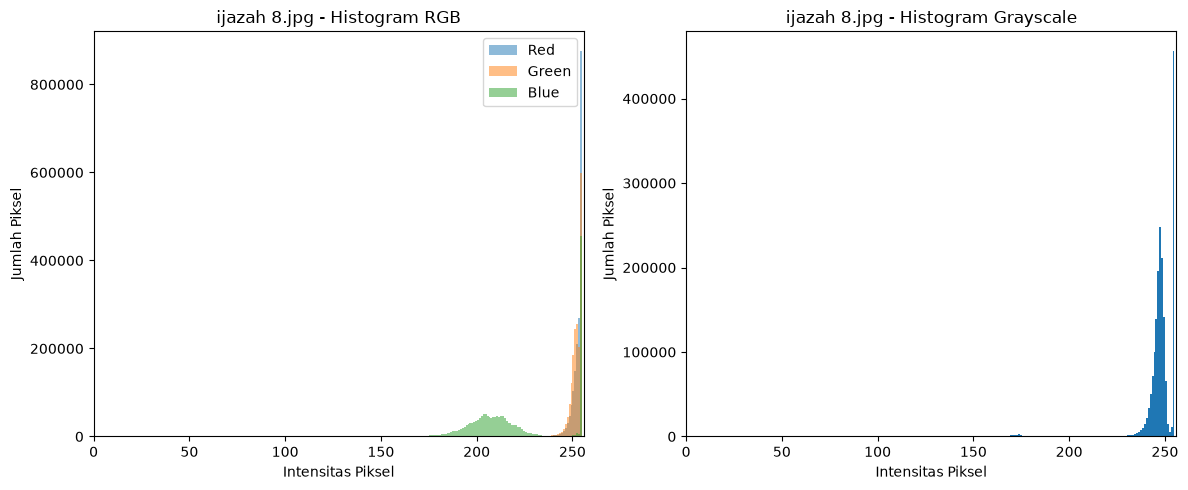

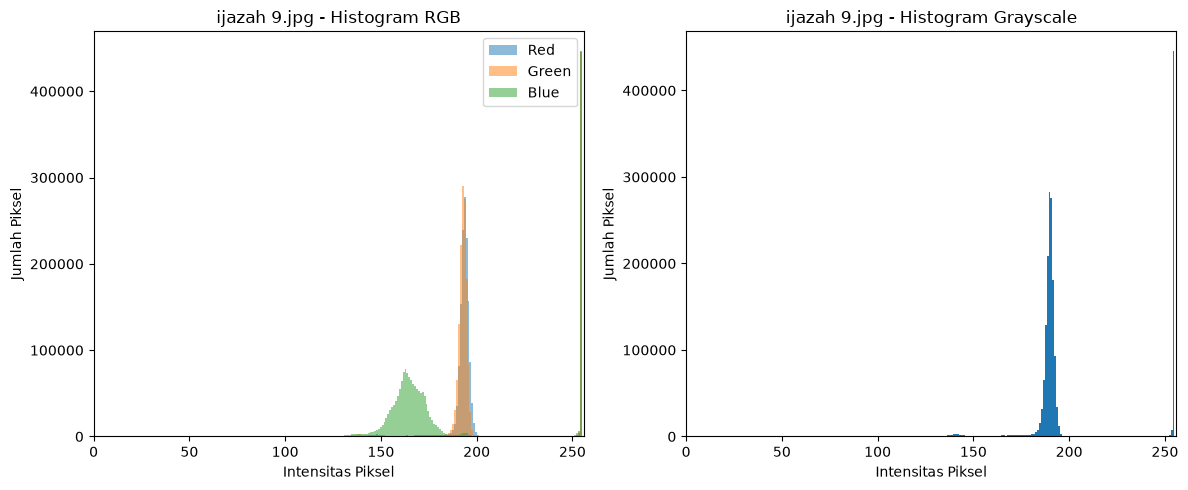

In [5]:
for file in jpg_files:
    
    # Membaca gambar
    img_bgr = cv2.imread(file)
    
    # RGB
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    
    # Grayscale
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    
    nama = os.path.basename(file)
    
    # Membuat figure
    plt.figure(figsize=(12, 5))
    
    # Histogram RGB
    plt.subplot(1, 2, 1)
    
    plt.hist(img_rgb[:, :, 0].ravel(), bins=256, alpha=0.5, label="Red")
    plt.hist(img_rgb[:, :, 1].ravel(), bins=256, alpha=0.5, label="Green")
    plt.hist(img_rgb[:, :, 2].ravel(), bins=256, alpha=0.5, label="Blue")
    
    plt.title(f"{nama} - Histogram RGB")
    plt.xlabel("Intensitas Piksel")
    plt.ylabel("Jumlah Piksel")
    plt.legend()
    plt.xlim([0, 256])
    
    # Histogram Grayscale
    plt.subplot(1, 2, 2)
    
    plt.hist(gray.ravel(), bins=256)
    
    plt.title(f"{nama} - Histogram Grayscale")
    plt.xlabel("Intensitas Piksel")
    plt.ylabel("Jumlah Piksel")
    plt.xlim([0, 256])
    
    plt.tight_layout()
    plt.show()

In [10]:
import cv2
import numpy as np
import pandas as pd
import os

hasil_analisis = []

for file in jpg_files:
    img = cv2.imread(file)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Statistik intensitas
    mean = np.mean(gray)
    std = np.std(gray)
    minimum = np.min(gray)
    maksimum = np.max(gray)
    
    # Persentase piksel gelap dan terang
    persen_gelap = np.mean(gray < 60) * 100
    persen_terang = np.mean(gray > 200) * 100

    hasil_analisis.append({
        "Citra": os.path.basename(file),
        "Mean": round(mean, 2),
        "Std": round(std, 2),
        "Min": minimum,
        "Max": maksimum,
        "Gelap (%)": round(persen_gelap, 2),
        "Terang (%)": round(persen_terang, 2)
    })

df = pd.DataFrame(hasil_analisis)

df

,Citra,Mean,Std,Min,Max,Gelap (%),Terang (%)
0,ijazah 1.jpg,178.39,44.75,0,255,0.23,23.62
1,ijazah 2.jpg,236.59,29.85,0,255,0.53,94.86
2,ijazah 3.jpg,236.35,30.33,0,255,0.57,94.77
3,ijazah 4.jpg,241.06,33.99,0,255,1.32,94.79
4,ijazah 5.jpg,242.84,26.77,0,255,0.26,94.28
5,ijazah 6.jpg,242.61,29.35,0,255,0.40,94.73
6,ijazah 7.jpg,242.80,20.31,0,255,0.12,95.81
7,ijazah 8.jpg,242.28,30.30,0,255,0.51,94.95
8,ijazah 9.jpg,200.95,35.79,0,255,0.36,23.61


In [11]:
def klasifikasi_citra(row):
    mean = row["Mean"]
    std = row["Std"]
    gelap = row["Gelap (%)"]
    terang = row["Terang (%)"]

    masalah = []

    if mean < 90 or gelap > 40:
        masalah.append("Cenderung terlalu gelap")

    if mean > 180 or terang > 40:
        masalah.append("Cenderung terlalu terang")

    if std < 40:
        masalah.append("Kontras relatif rendah")

    if len(masalah) == 0:
        masalah.append("Tidak ada masalah utama berdasarkan statistik")

    return ", ".join(masalah)


df["Analisis Awal"] = df.apply(klasifikasi_citra, axis=1)

df

,Citra,Mean,Std,Min,Max,Gelap (%),Terang (%),Analisis Awal
0,ijazah 1.jpg,178.39,44.75,0,255,0.23,23.62,Tidak ada masalah utama berdasarkan statistik
1,ijazah 2.jpg,236.59,29.85,0,255,0.53,94.86,"Cenderung terlalu terang, Kontras relatif rendah"
2,ijazah 3.jpg,236.35,30.33,0,255,0.57,94.77,"Cenderung terlalu terang, Kontras relatif rendah"
3,ijazah 4.jpg,241.06,33.99,0,255,1.32,94.79,"Cenderung terlalu terang, Kontras relatif rendah"
4,ijazah 5.jpg,242.84,26.77,0,255,0.26,94.28,"Cenderung terlalu terang, Kontras relatif rendah"
5,ijazah 6.jpg,242.61,29.35,0,255,0.40,94.73,"Cenderung terlalu terang, Kontras relatif rendah"
6,ijazah 7.jpg,242.80,20.31,0,255,0.12,95.81,"Cenderung terlalu terang, Kontras relatif rendah"
7,ijazah 8.jpg,242.28,30.30,0,255,0.51,94.95,"Cenderung terlalu terang, Kontras relatif rendah"
8,ijazah 9.jpg,200.95,35.79,0,255,0.36,23.61,"Cenderung terlalu terang, Kontras relatif rendah"


In [12]:
df[[
    "Citra",
    "Mean",
    "Std",
    "Gelap (%)",
    "Terang (%)",
    "Analisis Awal"
]]

,Citra,Mean,Std,Gelap (%),Terang (%),Analisis Awal
0,ijazah 1.jpg,178.39,44.75,0.23,23.62,Tidak ada masalah utama berdasarkan statistik
1,ijazah 2.jpg,236.59,29.85,0.53,94.86,"Cenderung terlalu terang, Kontras relatif rendah"
2,ijazah 3.jpg,236.35,30.33,0.57,94.77,"Cenderung terlalu terang, Kontras relatif rendah"
3,ijazah 4.jpg,241.06,33.99,1.32,94.79,"Cenderung terlalu terang, Kontras relatif rendah"
4,ijazah 5.jpg,242.84,26.77,0.26,94.28,"Cenderung terlalu terang, Kontras relatif rendah"
5,ijazah 6.jpg,242.61,29.35,0.40,94.73,"Cenderung terlalu terang, Kontras relatif rendah"
6,ijazah 7.jpg,242.80,20.31,0.12,95.81,"Cenderung terlalu terang, Kontras relatif rendah"
7,ijazah 8.jpg,242.28,30.30,0.51,94.95,"Cenderung terlalu terang, Kontras relatif rendah"
8,ijazah 9.jpg,200.95,35.79,0.36,23.61,"Cenderung terlalu terang, Kontras relatif rendah"


In [13]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def gamma_correction(image, gamma=1.5):
    # Normalisasi piksel ke 0-1
    normalized = image / 255.0
    
    # Gamma correction
    corrected = np.power(normalized, gamma)
    
    # Kembalikan ke 0-255
    corrected = np.uint8(corrected * 255)
    
    return corrected


def histogram_equalization(image):
    return cv2.equalizeHist(image)


def clahe_enhancement(image):
    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )
    return clahe.apply(image)


def median_filter(image):
    return cv2.medianBlur(image, 5)


def gaussian_filter(image):
    return cv2.GaussianBlur(image, (5, 5), 0)

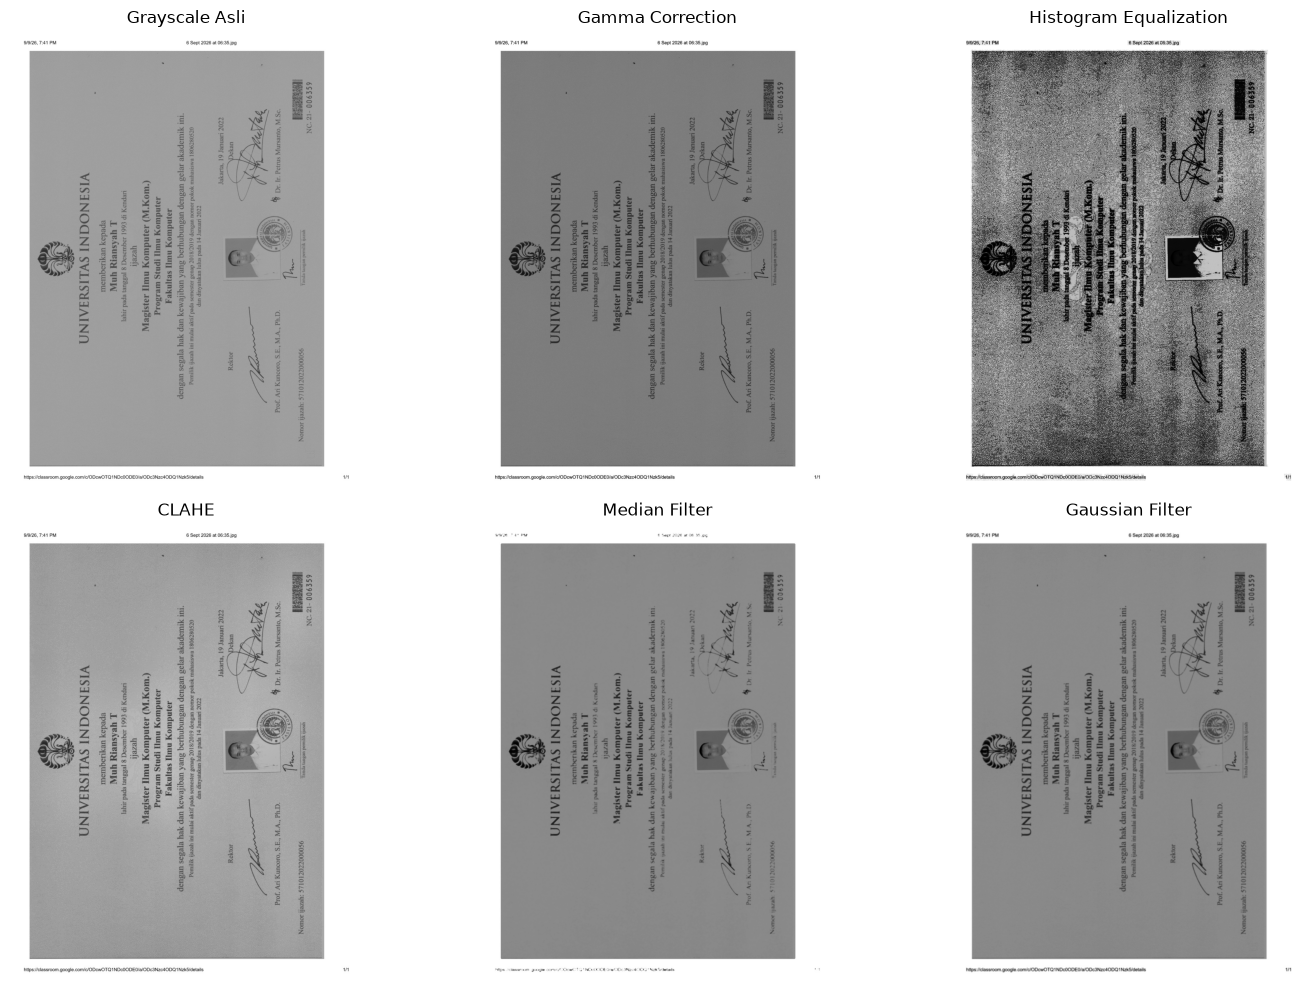

In [14]:
# Ambil gambar pertama
file = jpg_files[0]

img = cv2.imread(file)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Enhancement
gamma = gamma_correction(gray, gamma=1.5)
hist_eq = histogram_equalization(gray)
clahe = clahe_enhancement(gray)
median = median_filter(gray)
gaussian = gaussian_filter(gray)

# Tampilkan hasil
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale Asli")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(gamma, cmap="gray")
plt.title("Gamma Correction")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(hist_eq, cmap="gray")
plt.title("Histogram Equalization")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(clahe, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(median, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(gaussian, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

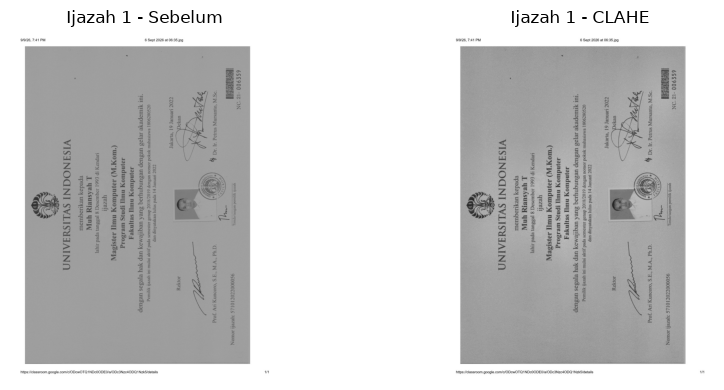

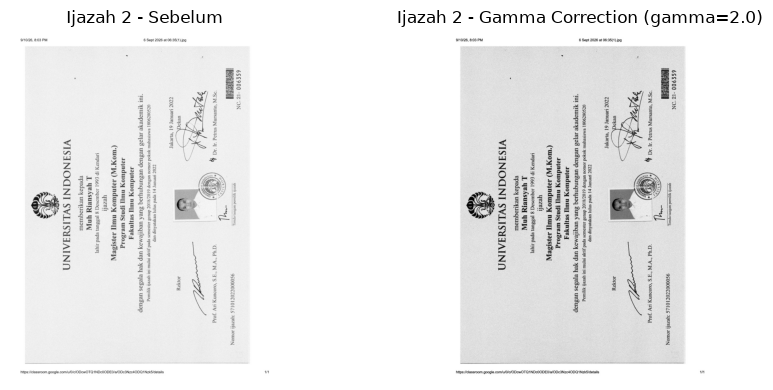

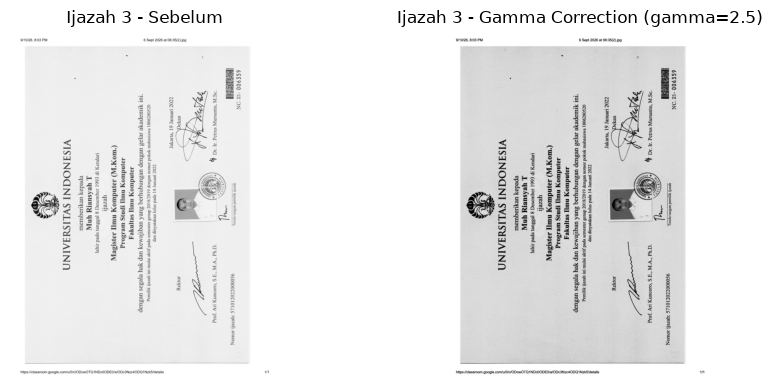

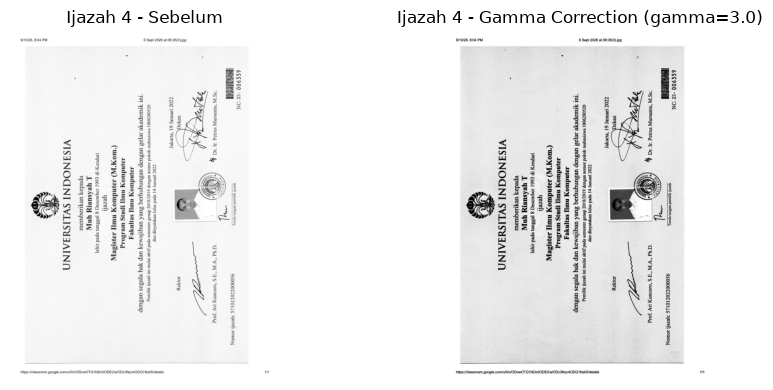

In [15]:
# Enhancement khusus untuk Ijazah 1-4

hasil_enhancement = {}

for i, file in enumerate(jpg_files[:4], start=1):

    img = cv2.imread(file)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    if i == 1:
        # Ijazah 1: kontras rendah
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )
        enhanced = clahe.apply(gray)
        metode = "CLAHE"

    elif i == 2:
        # Ijazah 2: terlalu terang
        enhanced = gamma_correction(gray, gamma=2.0)
        metode = "Gamma Correction (gamma=2.0)"

    elif i == 3:
        # Ijazah 3: terlalu terang
        enhanced = gamma_correction(gray, gamma=2.5)
        metode = "Gamma Correction (gamma=2.5)"

    elif i == 4:
        # Ijazah 4: sangat terang
        enhanced = gamma_correction(gray, gamma=3.0)
        metode = "Gamma Correction (gamma=3.0)"

    hasil_enhancement[i] = enhanced

    # Menampilkan perbandingan
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(gray, cmap="gray")
    plt.title(f"Ijazah {i} - Sebelum")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(enhanced, cmap="gray")
    plt.title(f"Ijazah {i} - {metode}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()
    

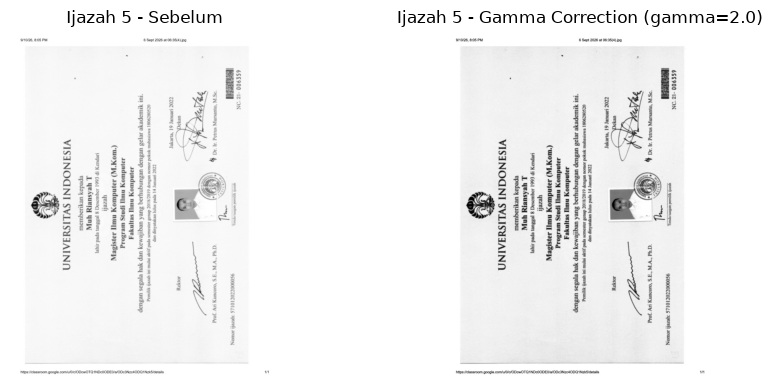

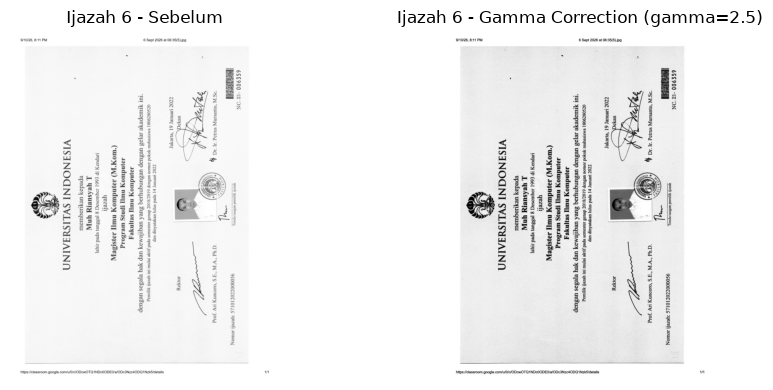

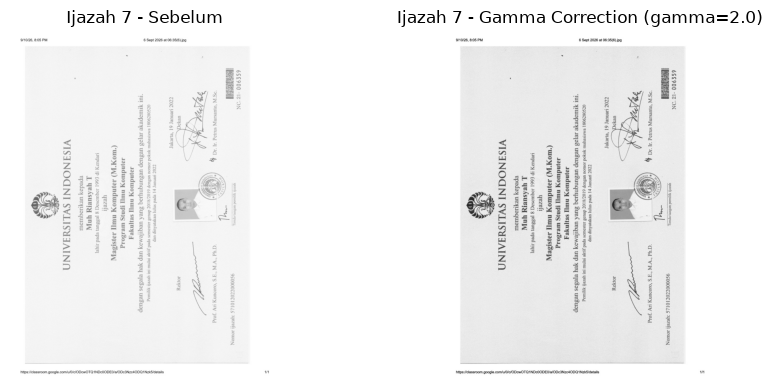

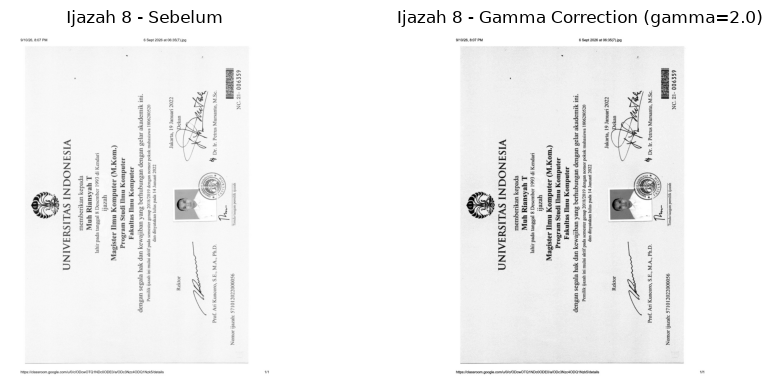

In [16]:
# Enhancement untuk Ijazah 5-8

for i in range(5, 9):

    file = jpg_files[i - 1]

    img = cv2.imread(file)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Gamma > 1 digunakan untuk mengurangi kecerahan
    if i == 5:
        enhanced = gamma_correction(gray, gamma=2.0)
        metode = "Gamma Correction (gamma=2.0)"

    elif i == 6:
        enhanced = gamma_correction(gray, gamma=2.5)
        metode = "Gamma Correction (gamma=2.5)"

    elif i == 7:
        enhanced = gamma_correction(gray, gamma=2.0)
        metode = "Gamma Correction (gamma=2.0)"

    elif i == 8:
        enhanced = gamma_correction(gray, gamma=2.0)
        metode = "Gamma Correction (gamma=2.0)"

    # Simpan hasil
    hasil_enhancement[i] = enhanced

    # Tampilkan sebelum dan sesudah
    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    plt.imshow(gray, cmap="gray")
    plt.title(f"Ijazah {i} - Sebelum")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(enhanced, cmap="gray")
    plt.title(f"Ijazah {i} - {metode}")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

In [17]:
import cv2
import os
import matplotlib.pyplot as plt

# Membuat folder hasil jika belum ada
os.makedirs("hasil", exist_ok=True)

hasil_enhancement = {}

for i, file in enumerate(jpg_files, start=1):

    # Membaca gambar
    img = cv2.imread(file)

    # Mengubah menjadi grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Menentukan metode berdasarkan hasil analisis
    if i == 1:
        # Ijazah 1: kontras rendah
        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )
        enhanced = clahe.apply(gray)
        metode = "CLAHE"

    else:
        # Ijazah 2-9: terlalu terang
        # Gamma > 1 digunakan untuk mengurangi kecerahan
        gamma = 2.0
        normalized = gray / 255.0
        enhanced = np.power(normalized, gamma)
        enhanced = np.uint8(enhanced * 255)
        metode = "Gamma Correction"

    # Menyimpan hasil dalam dictionary
    hasil_enhancement[i] = enhanced

    # Nama file output
    nama_file = os.path.basename(file)
    nama_tanpa_ext = os.path.splitext(nama_file)[0]

    output_path = os.path.join(
        "hasil",
        f"{nama_tanpa_ext}_enhanced.jpg"
    )

    # Simpan gambar
    cv2.imwrite(output_path, enhanced)

    print(f"Ijazah {i}: {metode}")
    print(f"Disimpan: {output_path}")

Ijazah 1: CLAHE
Disimpan: hasil\ijazah 1_enhanced.jpg
Ijazah 2: Gamma Correction
Disimpan: hasil\ijazah 2_enhanced.jpg
Ijazah 3: Gamma Correction
Disimpan: hasil\ijazah 3_enhanced.jpg
Ijazah 4: Gamma Correction
Disimpan: hasil\ijazah 4_enhanced.jpg
Ijazah 5: Gamma Correction
Disimpan: hasil\ijazah 5_enhanced.jpg
Ijazah 6: Gamma Correction
Disimpan: hasil\ijazah 6_enhanced.jpg
Ijazah 7: Gamma Correction
Disimpan: hasil\ijazah 7_enhanced.jpg
Ijazah 8: Gamma Correction
Disimpan: hasil\ijazah 8_enhanced.jpg
Ijazah 9: Gamma Correction
Disimpan: hasil\ijazah 9_enhanced.jpg


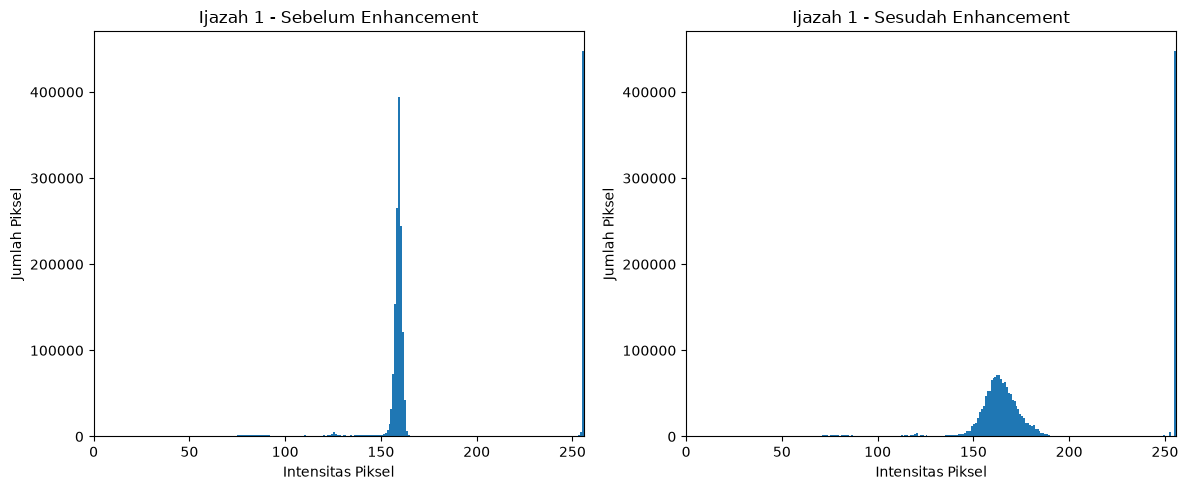

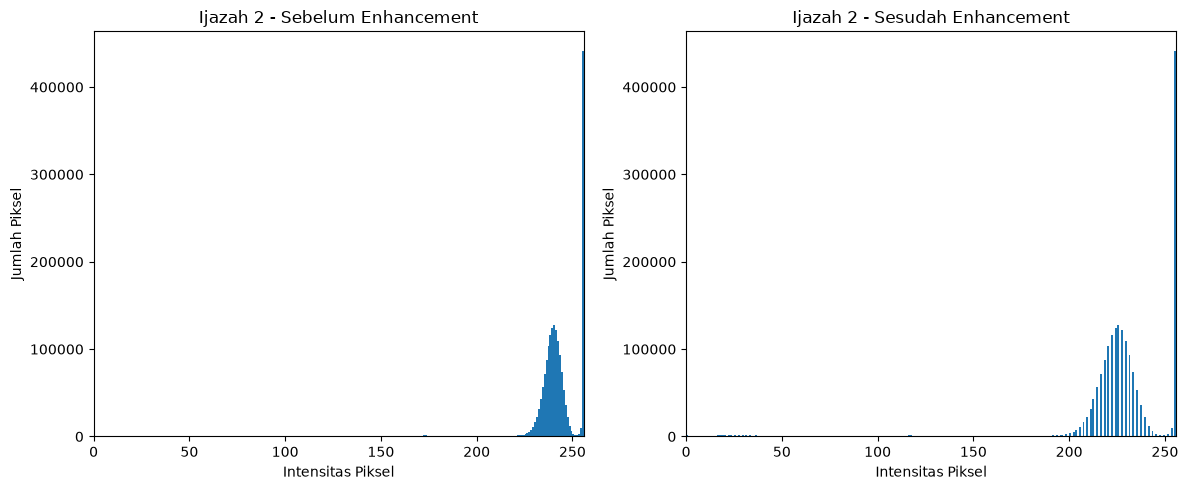

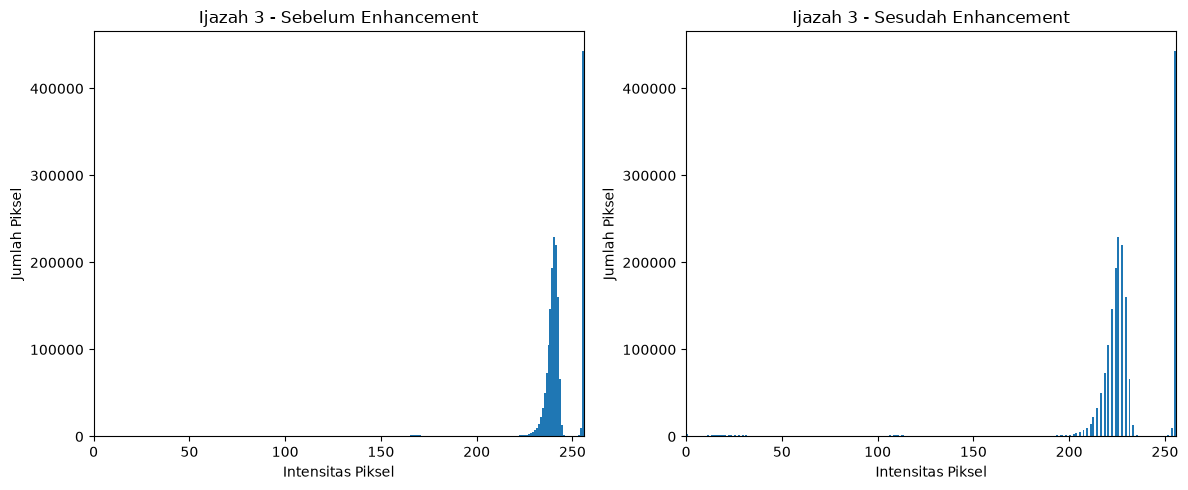

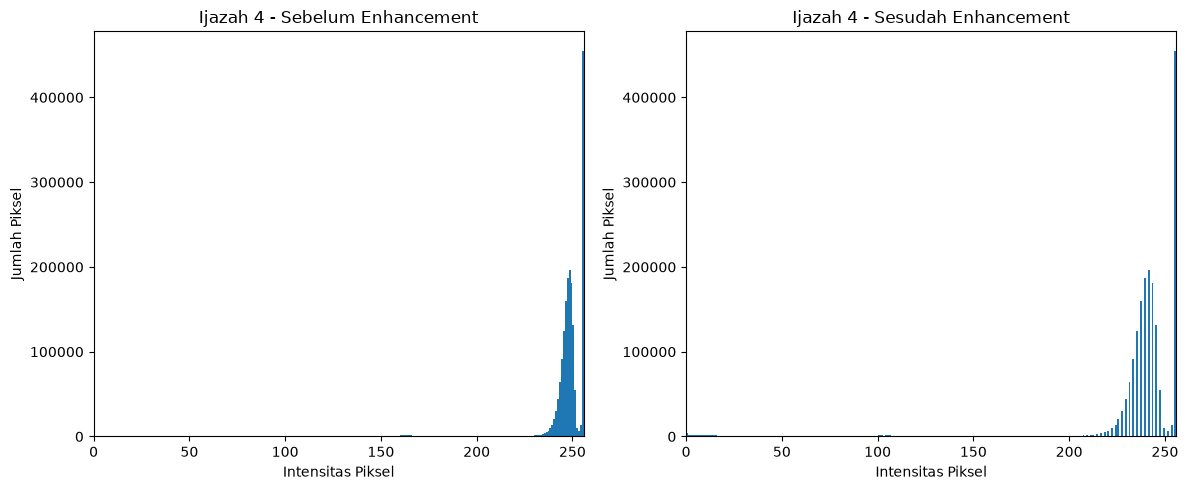

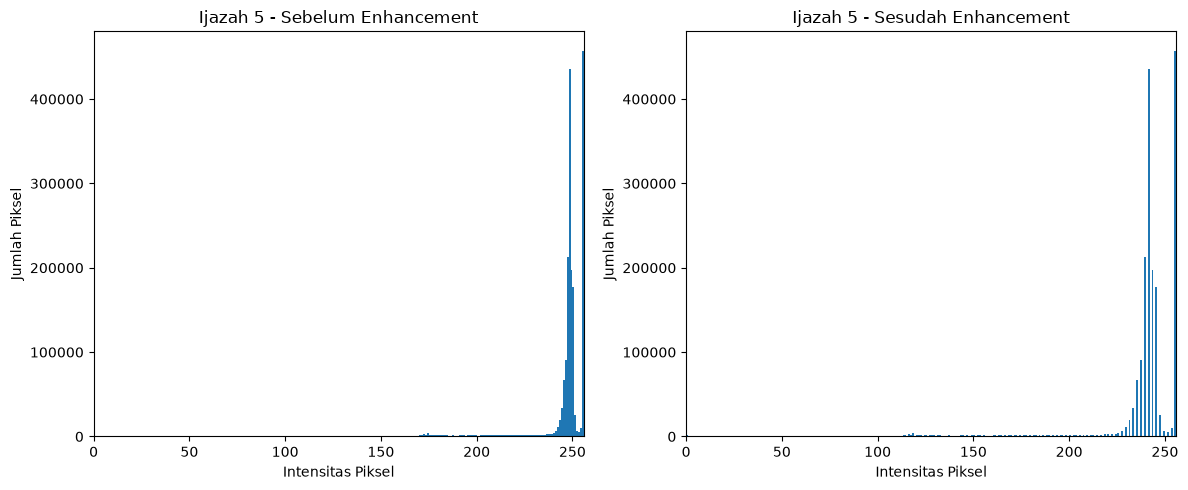

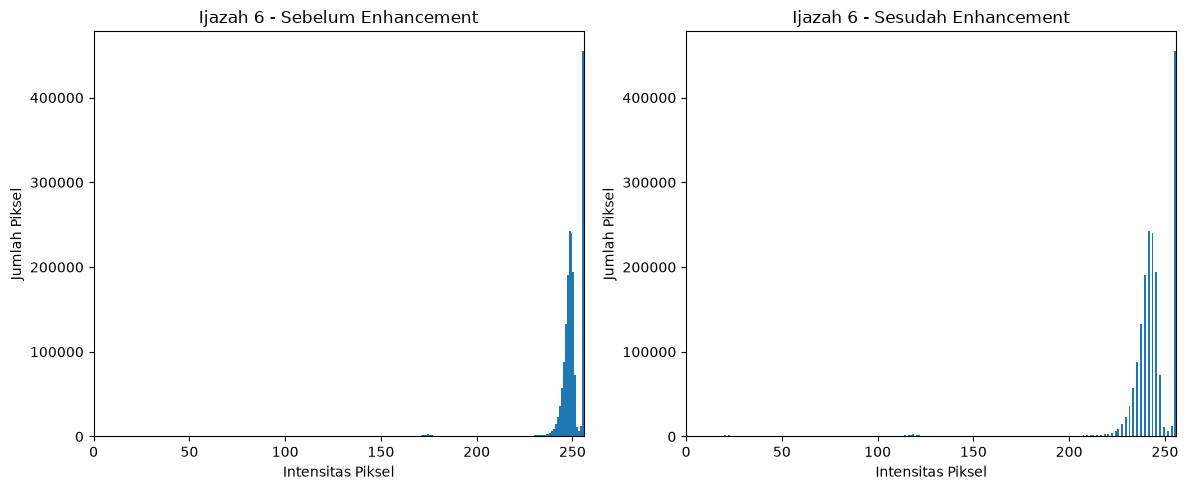

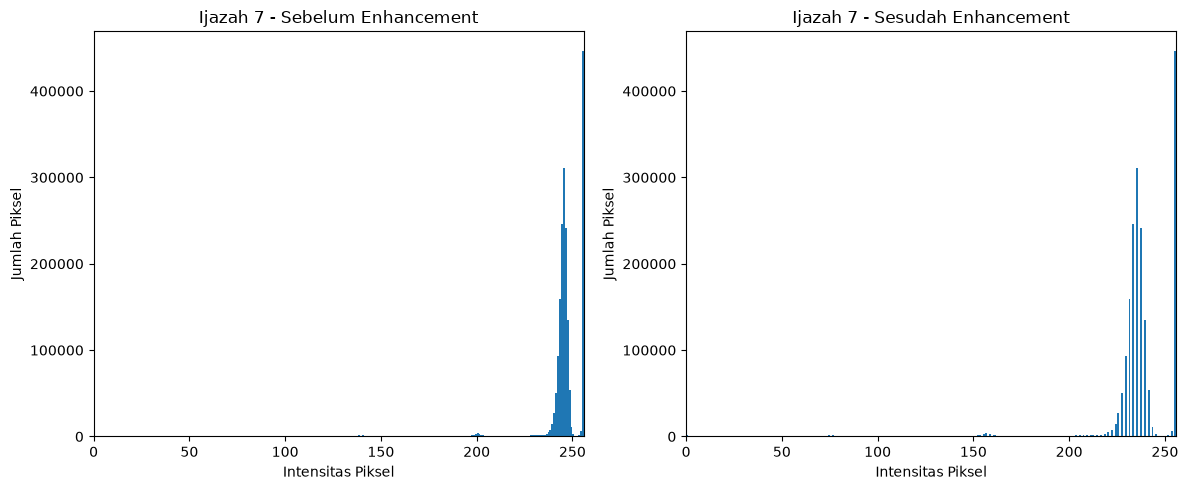

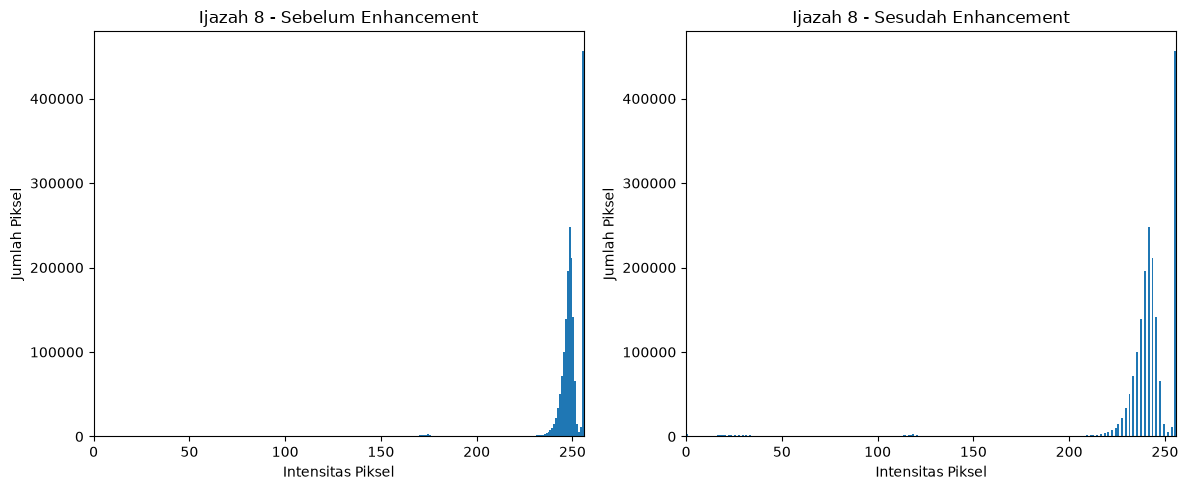

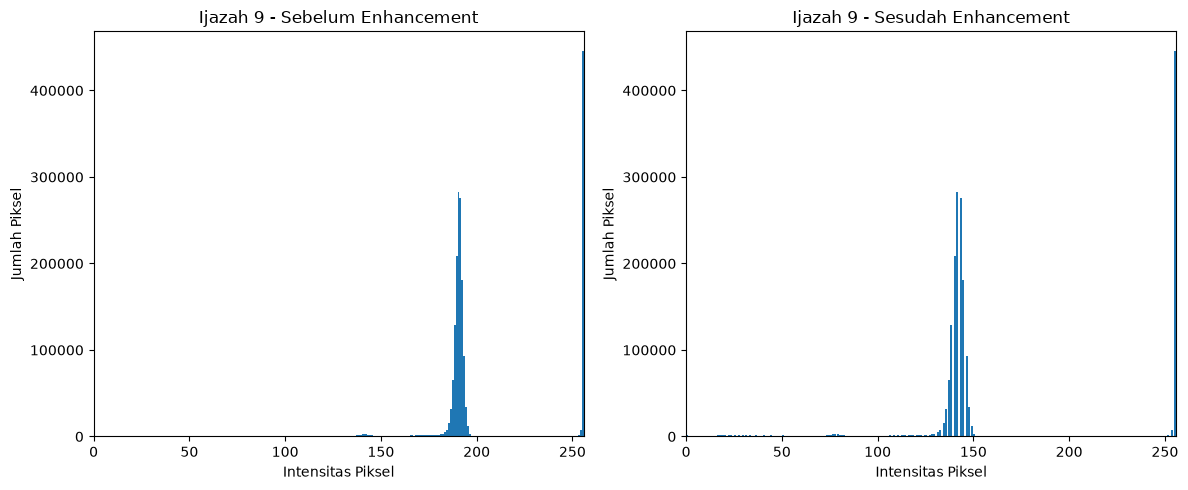

In [18]:
for i, file in enumerate(jpg_files, start=1):

    # Membaca citra asli
    img = cv2.imread(file)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Mengambil hasil enhancement
    enhanced = hasil_enhancement[i]

    plt.figure(figsize=(12, 5))

    # Histogram sebelum enhancement
    plt.subplot(1, 2, 1)
    plt.hist(gray.ravel(), bins=256, range=[0, 256])
    plt.title(f"Ijazah {i} - Sebelum Enhancement")
    plt.xlabel("Intensitas Piksel")
    plt.ylabel("Jumlah Piksel")
    plt.xlim([0, 256])

    # Histogram sesudah enhancement
    plt.subplot(1, 2, 2)
    plt.hist(enhanced.ravel(), bins=256, range=[0, 256])
    plt.title(f"Ijazah {i} - Sesudah Enhancement")
    plt.xlabel("Intensitas Piksel")
    plt.ylabel("Jumlah Piksel")
    plt.xlim([0, 256])

    plt.tight_layout()
    plt.show()

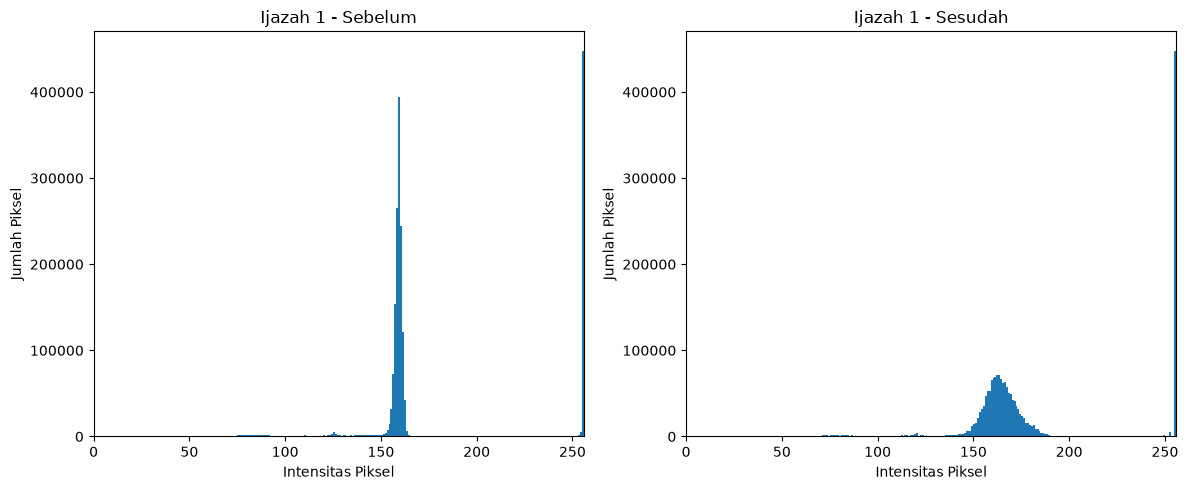

Disimpan: hasil/histogram/ijazah_1_histogram.png


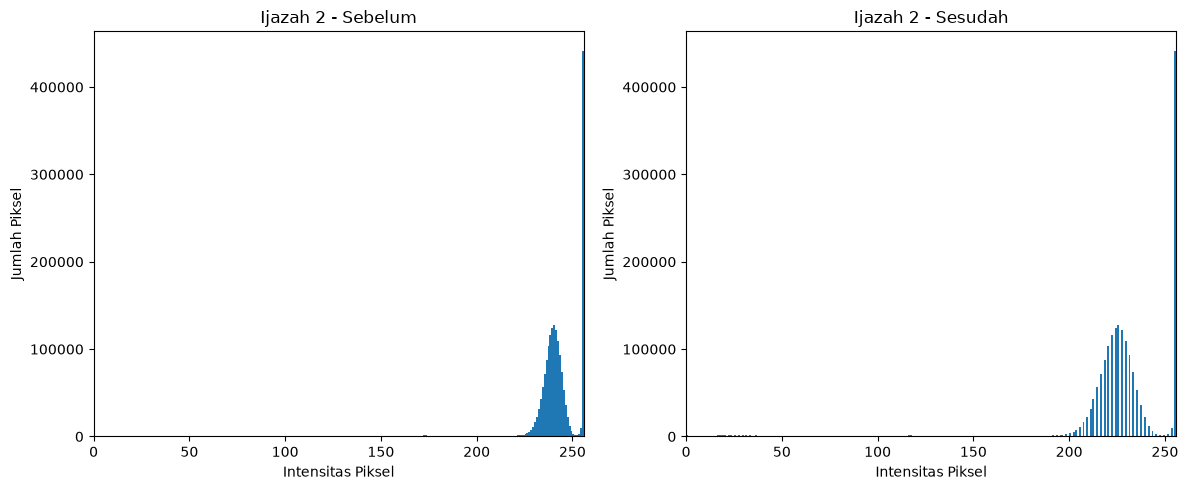

Disimpan: hasil/histogram/ijazah_2_histogram.png


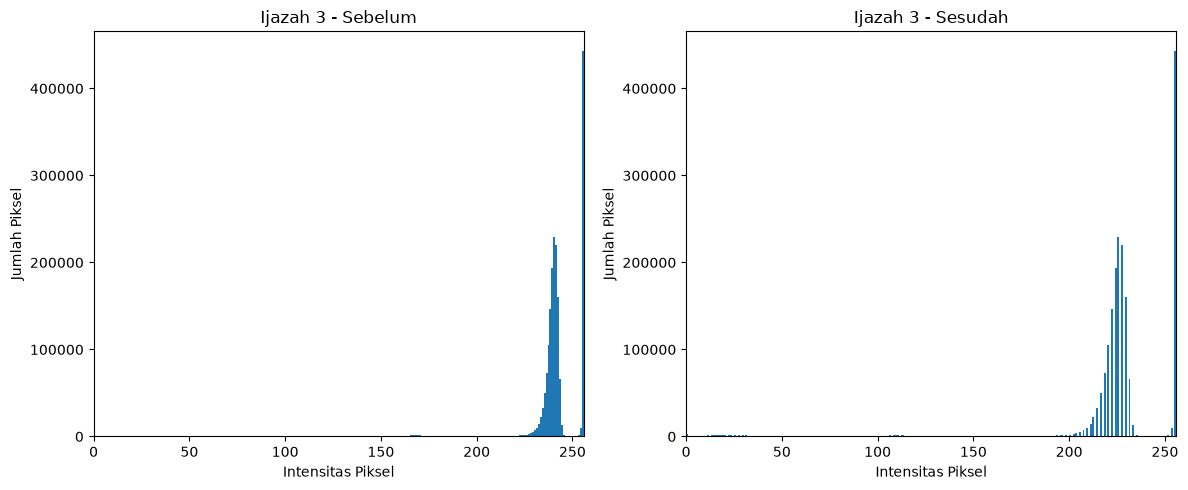

Disimpan: hasil/histogram/ijazah_3_histogram.png


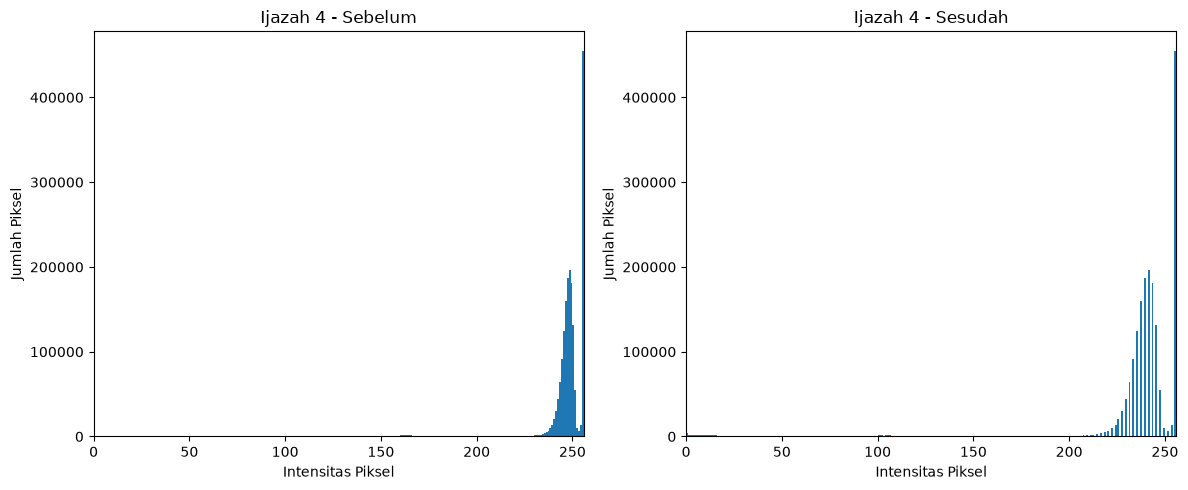

Disimpan: hasil/histogram/ijazah_4_histogram.png


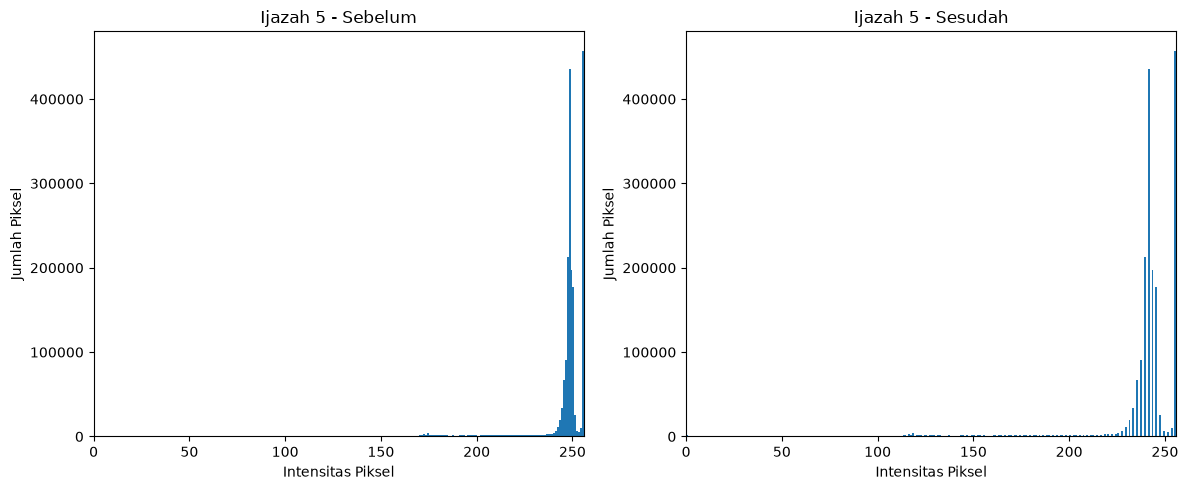

Disimpan: hasil/histogram/ijazah_5_histogram.png


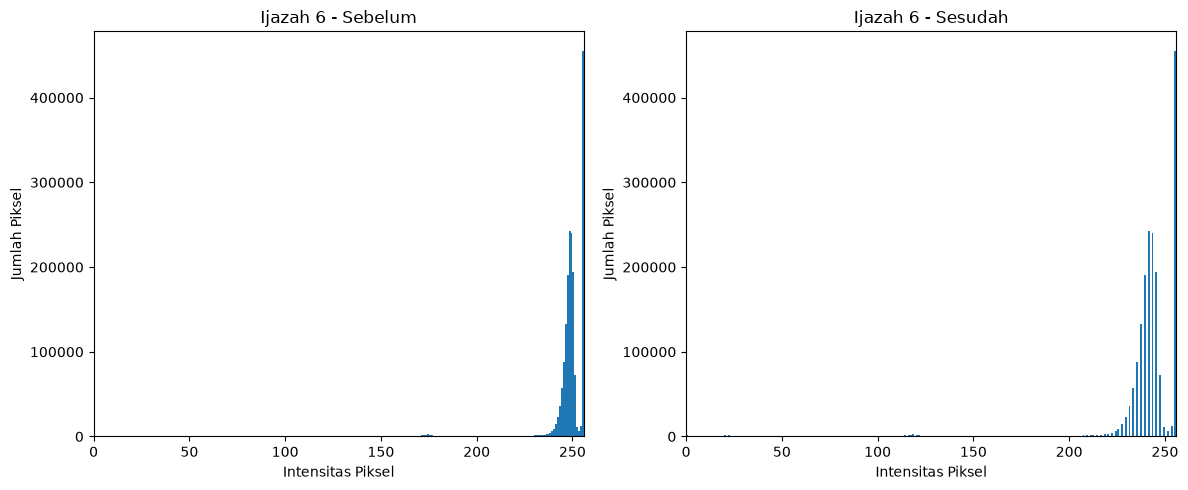

Disimpan: hasil/histogram/ijazah_6_histogram.png


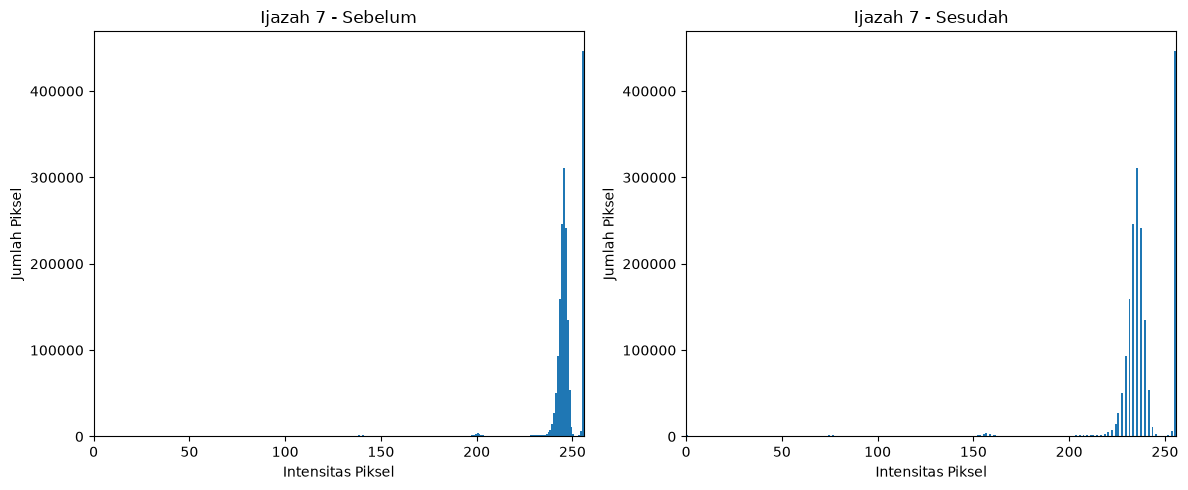

Disimpan: hasil/histogram/ijazah_7_histogram.png


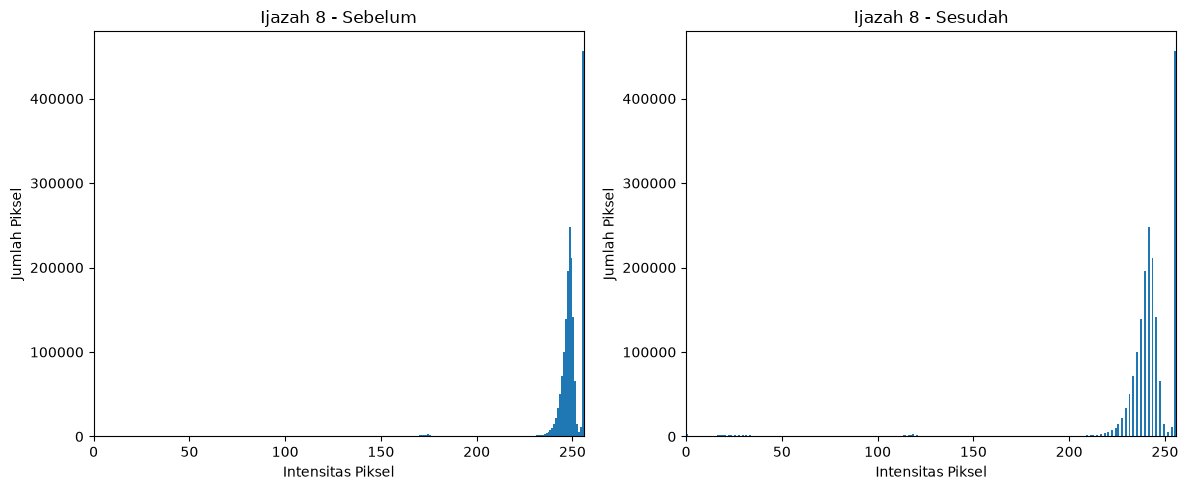

Disimpan: hasil/histogram/ijazah_8_histogram.png


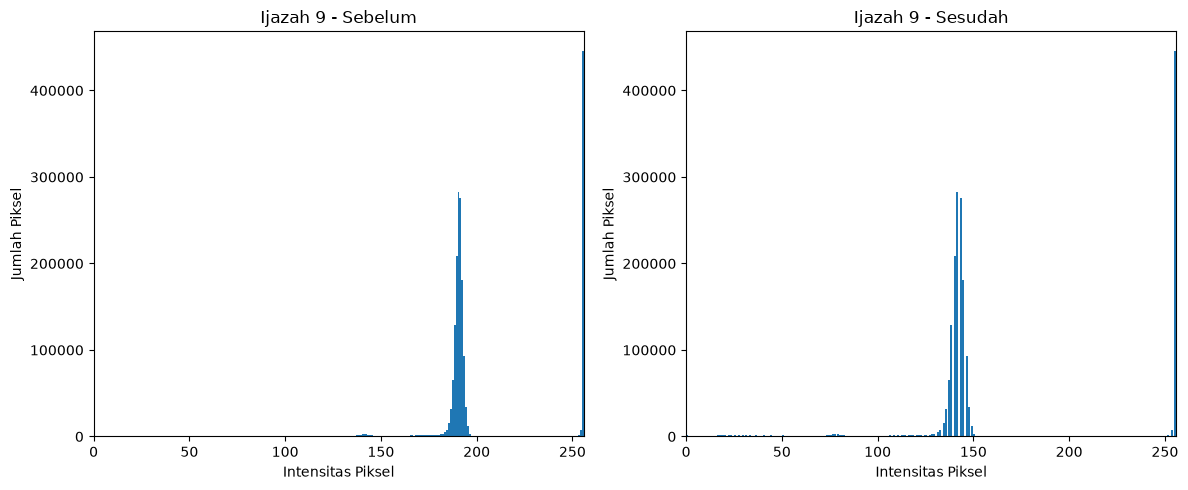

Disimpan: hasil/histogram/ijazah_9_histogram.png


In [19]:
os.makedirs("hasil/histogram", exist_ok=True)

for i, file in enumerate(jpg_files, start=1):

    img = cv2.imread(file)
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    enhanced = hasil_enhancement[i]

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.hist(gray.ravel(), bins=256, range=[0, 256])
    plt.title(f"Ijazah {i} - Sebelum")
    plt.xlabel("Intensitas Piksel")
    plt.ylabel("Jumlah Piksel")
    plt.xlim([0, 256])

    plt.subplot(1, 2, 2)
    plt.hist(enhanced.ravel(), bins=256, range=[0, 256])
    plt.title(f"Ijazah {i} - Sesudah")
    plt.xlabel("Intensitas Piksel")
    plt.ylabel("Jumlah Piksel")
    plt.xlim([0, 256])

    plt.tight_layout()

    output = f"hasil/histogram/ijazah_{i}_histogram.png"
    plt.savefig(output, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close()

    print(f"Disimpan: {output}")